# Project 2 — Scanned Document Classification

This notebook provides a starting point for the **Scanned Document Classification** project. We classify eight kinds of scanned business documents using text extracted by OCR. The baseline intentionally uses only **TF-IDF + Logistic Regression**; the original page images remain available for later image-based or multimodal experiments.

The retained classes are advertisement, email, form, invoice, letter, news article, presentation, and resume. Use the validation split for development and leave the test split untouched until final evaluation.

## 1. Your Tasks

The provided notebook establishes a simple baseline for detecting potentially toxic comments. Your task is to **evaluate this baseline, identify its limitations, and investigate possible improvements**.

### 1.1 Explore the Dataset

Get familiar with the data and the classification task.

- Examine the dataset characteristics, class distribution, and representative examples.
- Consider how the target labels are defined and whether the data is suitable for the intended application.
- Identify potential issues related to data quality, coverage, or representativeness.

### 1.2 Evaluate the Baseline

Determine how well the model performs and which evaluation criteria are appropriate.

- Select and justify metrics relevant to the content moderation task.
- Evaluate overall and class-wise performance.
- Consider the consequences of different types of errors, particularly false positives and false negatives.

### 1.3 Analyze Errors and Diagnose Limitations

Investigate where and why the classifier makes mistakes.

- Examine misclassified examples and identify recurring patterns.
- Formulate possible explanations for the observed errors.
- Distinguish observations supported by the data from hypotheses that require further investigation.

### 1.4 Investigate Possible Improvements

Based on your observations and relevant literature, identify promising directions for improving the baseline.

- Research alternative approaches, representations, or model configurations.
- Explain which limitations these approaches might address.
- Where feasible, implement and evaluate an improvement against the original baseline using a consistent evaluation setup.

### 1.5 Document Your Findings

Summarize your experiments and the reasoning behind your decisions.

- What did you investigate, and why?
- What evidence supports your observations and conclusions?
- Which improvements appear promising, and what remains unresolved?

**Important:** Your decisions should be grounded in **empirical evidence or relevant research**, rather than assumptions. When proposing changes, explain the motivation and evaluate their effects whenever possible.

Use the validation set for model development and comparisons. Keep the test set reserved for final evaluation.



## 2. Starter code 

### 2.1 Prepare the dataset

Run the preparation script once from the repository root before opening this notebook. It reads the already-downloaded local dataset, samples reproducibly, copies selected images to a separate project directory, and caches Tesseract OCR. It never changes the source dataset.

```bash
sudo apt-get install tesseract-ocr tesseract-ocr-eng
python -m pip install pytesseract

python scripts/download_dataset.py "abarsky/rvl_cdip_small" "data/rvl_cdip_small"

python project_baselines/project_02/scripts/prepare_rvl_cdip_small.py \
  --examples-per-class 50 \
  --seed 42
```

By default, the script reads `data/rvl_cdip_small` and writes `project_baselines/project_02/data/prepared/rvl_cdip_small`. See `README.md` and `python scripts/prepare_rvl_cdip_small.py --help` for overrides.

Notice that above we only have 50 examples per class, which leaves only ~5 examples for validation. Increase that number to test with more documents.

### 2.2 Load and inspect the prepared data

Now that the data is local, you can load the dataset. 

In [1]:
import os
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

# This works when Jupyter starts either in this project folder or at repository root.
project_dir = Path.cwd()
if not (project_dir / "scripts" / "prepare_rvl_cdip_small.py").exists():
    project_dir = project_dir / "project_baselines" / "project_02"
if not (project_dir / "scripts" / "prepare_rvl_cdip_small.py").exists():
    raise FileNotFoundError("Could not locate the project_02 directory.")

# RVL_CDIP_PREPARED_DIR is useful for temporary or shared data locations.
# CHANGED: use the larger prepared dataset (300 pages per class) instead of the default (20 per class)
data_dir = Path(
    os.environ.get(
        "RVL_CDIP_PREPARED_DIR",
        project_dir / "data" / "prepared" / "rvl_cdip_small_300",
    )
).expanduser().resolve()
manifest_path = data_dir / "dataset.csv"
if not manifest_path.exists():
    raise FileNotFoundError(
        f"Prepared manifest not found at {manifest_path}. Run the preparation command above first."
    )

documents = pd.read_csv(manifest_path).fillna({"ocr_text": ""})
required_columns = {"image_path", "ocr_text", "label", "source_split"}
if not required_columns.issubset(documents.columns):
    raise ValueError(f"Manifest is missing: {required_columns - set(documents.columns)}")

print(f"Loaded {len(documents):,} documents from {data_dir}")
display(pd.crosstab(documents["label"], documents["source_split"]))

Loaded 2,400 documents from /home/amaurya/hsbi-hitl-2026/project_baselines/project_02/data/prepared/rvl_cdip_small_300


source_split,test,train,validation
label,,,
advertisement,29,240,31
email,29,241,30
form,32,240,28
invoice,31,239,30
letter,31,238,31
news article,30,241,29
presentation,27,244,29
resume,32,241,27


### 2.3 Images and OCR examples

The OCR text is an imperfect representation of each page. Compare it with the image before drawing conclusions about model errors.

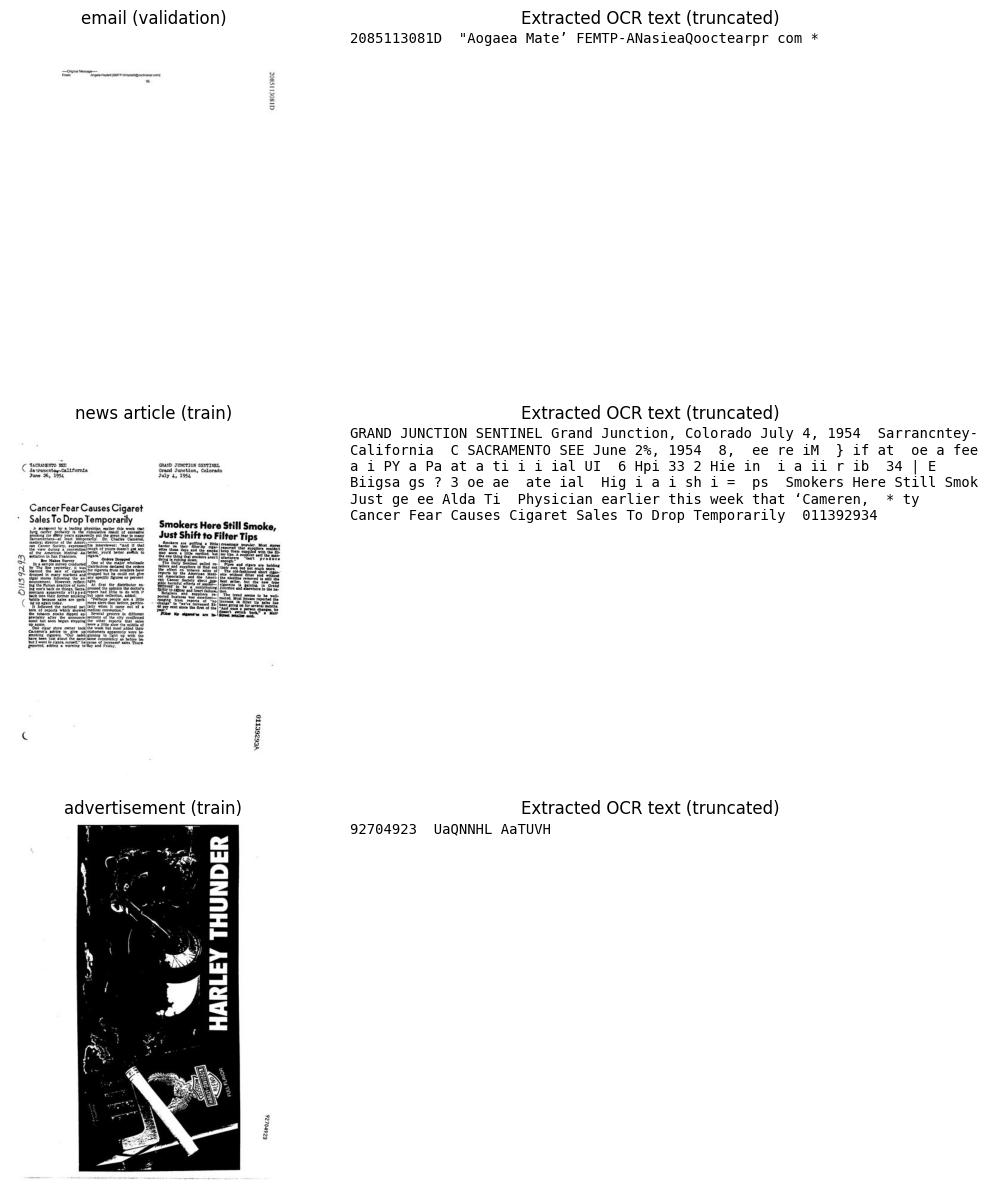

In [2]:
examples = (
    documents.groupby("label", group_keys=False)
    .sample(n=1, random_state=42)
    .sample(n=3, random_state=42)
)

fig, axes = plt.subplots(len(examples), 2, figsize=(13, 4 * len(examples)))
for row_number, (_, row) in enumerate(examples.iterrows()):
    image = Image.open(data_dir / row["image_path"])
    axes[row_number, 0].imshow(image, cmap="gray")
    axes[row_number, 0].set_title(f"{row['label']} ({row['source_split']})")
    axes[row_number, 0].axis("off")

    text = row["ocr_text"] or "[No OCR text extracted]"
    axes[row_number, 1].text(
        0, 1, textwrap.fill(text[:1_200], width=75), va="top", family="monospace"
    )
    axes[row_number, 1].set_title("Extracted OCR text (truncated)")
    axes[row_number, 1].axis("off")
plt.tight_layout()

### 2.4 Establishing a Baseline Classifier 

We prepare a TF-IDF + Logistic Regression baseline. We train only on the original training partition and evaluate on validation. Empty OCR is retained as an empty string rather than silently dropping difficult pages. The test partition is not used below.

In [3]:
train_df = documents[documents["source_split"] == "train"].copy()
validation_df = documents[documents["source_split"] == "validation"].copy()
test_df = documents[documents["source_split"] == "test"].copy()

if train_df.empty or validation_df.empty:
    raise ValueError("The prepared sample must contain train and validation examples.")

print(f"Train: {len(train_df)}, validation: {len(validation_df)}, reserved test: {len(test_df)}")
print(f"Empty OCR — train: {(train_df['ocr_text'].str.len() == 0).sum()}, validation: {(validation_df['ocr_text'].str.len() == 0).sum()}")

Train: 1924, validation: 235, reserved test: 241
Empty OCR — train: 18, validation: 4


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=20_000,
    sublinear_tf=True,
)
X_train = vectorizer.fit_transform(train_df["ocr_text"])
X_validation = vectorizer.transform(validation_df["ocr_text"])

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1_000,
    random_state=RANDOM_STATE,
)
model.fit(X_train, train_df["label"])
validation_predictions = model.predict(X_validation)
validation_probabilities = model.predict_proba(X_validation)

print("Training completed.")
print("TF-IDF representation:", X_train.shape)

Training completed.
TF-IDF representation: (1924, 20000)


### 2.5 Initial evaluation

Accuracy summarizes overall correctness. Macro-F1 gives every class equal weight and is useful even if a later sample is not perfectly balanced. The class-wise report and confusion matrix show where the baseline struggles.

Validation accuracy: 0.681
Validation macro-F1: 0.682

               precision    recall  f1-score   support

advertisement       0.52      0.84      0.64        31
        email       0.87      0.67      0.75        30
         form       0.76      0.57      0.65        28
      invoice       0.88      0.70      0.78        30
       letter       0.53      0.74      0.62        31
 news article       0.65      0.69      0.67        29
 presentation       0.59      0.34      0.43        29
       resume       0.92      0.89      0.91        27

     accuracy                           0.68       235
    macro avg       0.71      0.68      0.68       235
 weighted avg       0.71      0.68      0.68       235



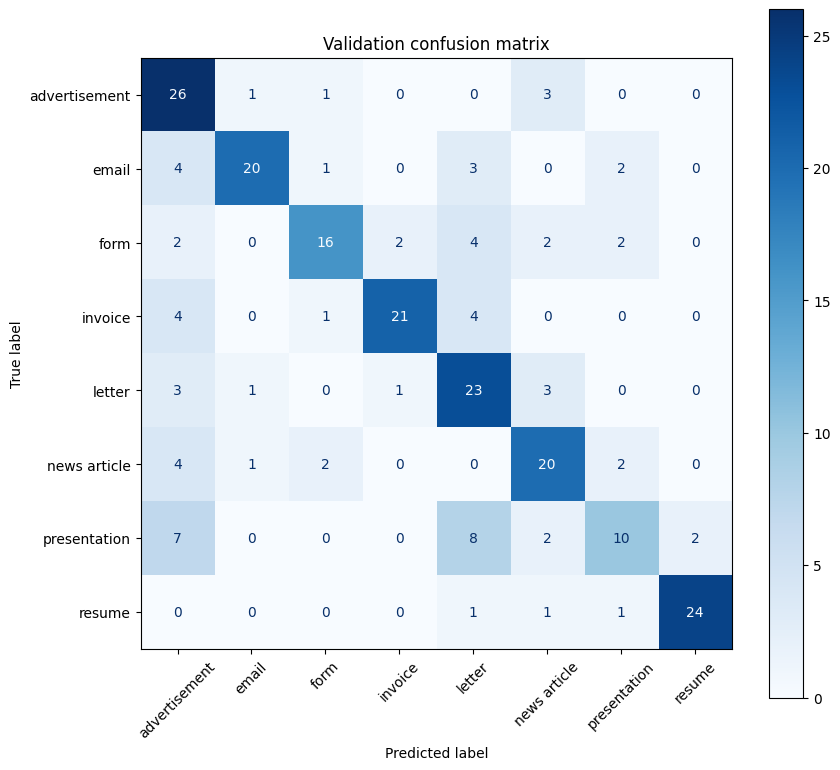

In [5]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)

accuracy = accuracy_score(validation_df["label"], validation_predictions)
macro_f1 = f1_score(validation_df["label"], validation_predictions, average="macro")
print(f"Validation accuracy: {accuracy:.3f}")
print(f"Validation macro-F1: {macro_f1:.3f}\n")
print(
    classification_report(
        validation_df["label"], validation_predictions, zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    validation_df["label"],
    validation_predictions,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax,
)
ax.set_title("Validation confusion matrix")
plt.tight_layout()

### 5.1 A small error table

This table is only a starting point. Inspect the corresponding images and ask whether each failure comes from OCR, limited training data, overlapping document types, or the text model itself.

In [6]:
validation_results = validation_df[["sample_id", "label", "image_path", "ocr_text"]].copy()
validation_results["prediction"] = validation_predictions
validation_results["confidence"] = validation_probabilities.max(axis=1)
errors = validation_results[
    validation_results["label"] != validation_results["prediction"]
].sort_values("confidence", ascending=False)
display(errors[["label", "prediction", "confidence", "ocr_text"]].head(10))

,label,prediction,confidence,ocr_text
2128,presentation,resume,0.734061,Migration and Cancer Nortality Experience--A S...
1932,advertisement,news article,0.434645,=a\n\not ‘Hel He (TO: imc ee on\n\n'Ranbenian ...
2032,invoice,letter,0.414186,Tobacco Company\n\n— RY Repwlr— op Q\n\nMA YOU...
1972,email,presentation,0.382696,Atremendous amount has been accomplished over ...
1959,email,letter,0.377238,"February 9, 1998\n\nDear Fellow Member of the ..."
2051,letter,news article,0.371706,@\n\namen A-ananane Bepartment of Agricaltare\...
2105,presentation,letter,0.338250,SEPARATE STATEMENT OF CHAIRMAN DIXON\n\nI Ginw...
2076,news article,presentation,0.328283,Appendix 4\nABI Study\n\nTH689-0596
2124,presentation,letter,0.317016,~ (IMFODATE\n\nReports on meetings and events ...
2055,letter,invoice,0.315707,|\n\nCRC CONTRACT RESEARCH CENTER avosssonr\n\...


## 3. Your experiments

### 3.1 Data exploration

**Setup.** We prepared a larger sample than the default (`--examples-per-class 300 --seed 42`): 2,400 pages, 300 per class, split into 1,924 train / 235 validation / 241 test (see the table in Section 2.2). The default sample (20 per class) gave only 2 validation pages per class, which made per-class results unreliable.

We explore only the **training and validation** pages. The test set stays untouched until the final evaluation.

**Questions:**
- How much text does OCR extract per class?
- How many pages have empty or very short OCR text?
- What do these difficult pages look like?

In [8]:
# Combine training and validation pages for exploration (test set stays untouched)
exploration_df = pd.concat([train_df, validation_df], ignore_index=True).copy()

# Number of words extracted by OCR for each page
exploration_df["n_words"] = exploration_df["ocr_text"].str.split().str.len()

ocr_summary = exploration_df.groupby("label").agg(
    pages=("label", "size"),
    median_words=("n_words", "median"),
    empty_ocr=("n_words", lambda s: (s == 0).sum()),
    short_ocr_under_20_words=("n_words", lambda s: (s < 20).sum()),
).sort_values("median_words")

display(ocr_summary)
print("Pages explored (train + validation):", len(exploration_df))
print("Total pages with empty OCR:", (exploration_df["n_words"] == 0).sum())
print("Total pages with fewer than 20 words:", (exploration_df["n_words"] < 20).sum())

,pages,median_words,empty_ocr,short_ocr_under_20_words
label,,,,
advertisement,271,24.0,8,120
email,271,63.0,0,38
presentation,273,66.0,6,74
invoice,269,84.0,4,31
news article,270,103.5,1,15
form,268,106.0,2,17
letter,269,159.0,1,8
resume,268,287.0,0,4


Pages explored (train + validation): 2159
Total pages with empty OCR: 22
Total pages with fewer than 20 words: 307


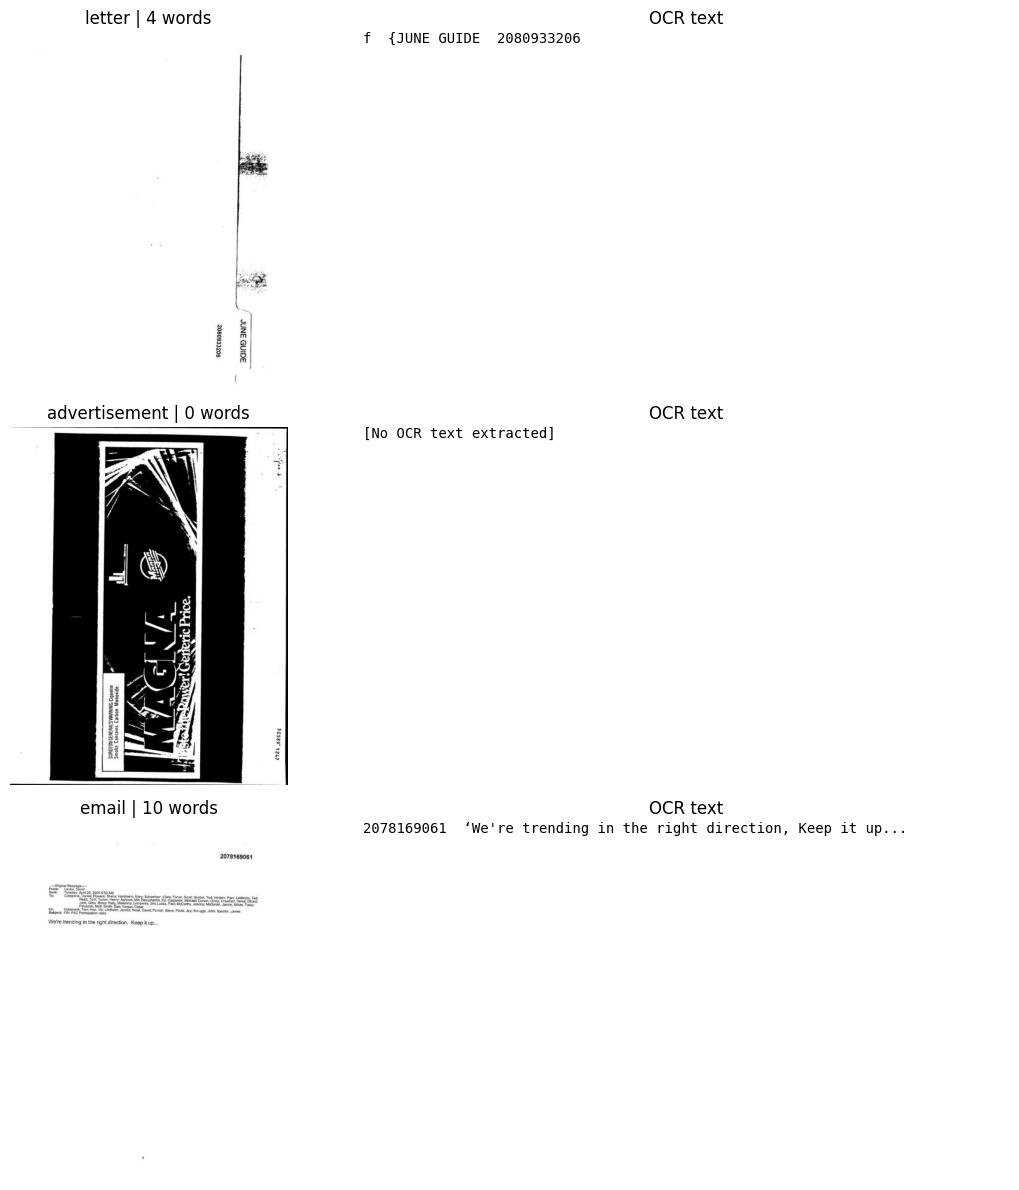

In [9]:
# Show 3 pages with very little OCR text: image next to the extracted text
short_pages = exploration_df[exploration_df["n_words"] < 20].sample(3, random_state=42)

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for i, (_, row) in enumerate(short_pages.iterrows()):
    axes[i, 0].imshow(Image.open(data_dir / row["image_path"]), cmap="gray")
    axes[i, 0].set_title(f"{row['label']} | {row['n_words']} words")
    axes[i, 0].axis("off")

    text = row["ocr_text"] or "[No OCR text extracted]"
    axes[i, 1].text(0, 1, textwrap.fill(text[:600], width=75), va="top", family="monospace")
    axes[i, 1].set_title("OCR text")
    axes[i, 1].axis("off")
plt.tight_layout()

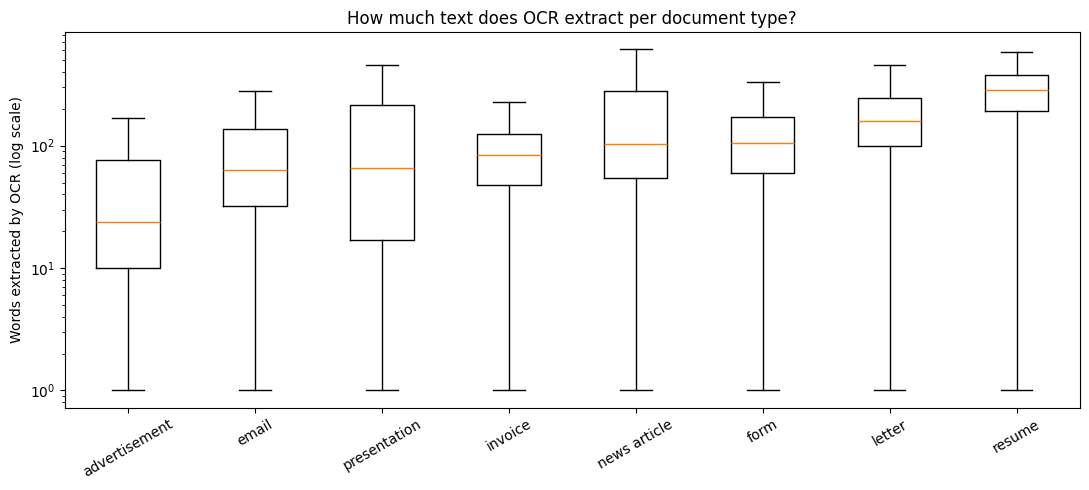

In [10]:
# EXTRA (optional): word-count distribution per class, a visual version of the table above
order = ocr_summary.index.tolist()
data = [exploration_df.loc[exploration_df["label"] == c, "n_words"].clip(lower=1) for c in order]

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels(order, rotation=30)
ax.set_yscale("log")
ax.set_ylabel("Words extracted by OCR (log scale)")
ax.set_title("How much text does OCR extract per document type?")
plt.tight_layout()

**Observations (3.1):**
- **The amount of OCR text differs a lot between classes.** Resumes have the most text (median 287 words), advertisements the least (median 24 words; 120 of 271 have fewer than 20 words).
- **Less text goes with weaker results.** Resume (most text) is the best class in the baseline (F1 0.91), while presentation (F1 0.43) and advertisement (F1 0.64) have little text. A text-only model has little to work with on these pages.
- **Presentation varies the most:** some slides contain a lot of text, many contain very little (widest box in the plot).
- **Some pages are mainly visual.** In the examples, an advertisement has no OCR text at all (it is a picture), and a "letter" page with 4 words looks like a folder tab rather than a letter. For such pages the image carries the information, or the label itself may be questionable.
- **Letter does not fit this pattern:** it has plenty of text but low precision (0.53), which suggests overlap with other text-heavy classes. We check this in the error analysis.

**Implication:** OCR text alone may not be enough for some classes. These short or visual pages are candidates for human review, and they motivate testing whether the page image adds information.

- **Representativeness:** the pages come from an old document collection (1980s–1990s tobacco-industry records, e.g. "Philip Morris"), mostly typewritten and scanned in low quality. Modern office documents (digital PDFs, different layouts) may look different, so results may not transfer directly (as the project description also notes).


### 3.2 Evaluating the baseline

**Metrics.** We use:
- **Macro-F1 (main metric):** every document type counts equally. A misrouted presentation matters as much as a misrouted invoice, and macro-F1 does not hide weak classes.
- **Accuracy:** easy to interpret (share of pages classified correctly). The classes are balanced (~30 validation pages each), so accuracy is not misleading here.
- **Per-class precision and recall** (Section 2.5): in multi-class classification, a false positive for one class is a false negative for another. Low **recall** means pages of that type are missed; low **precision** means other pages are wrongly sent to that type.

**Why errors matter:** a misclassified page is sent to the wrong workflow (e.g. an invoice treated as a letter may delay a payment). Pages the model is unsure about could instead be sent to a person for review.

We compare the model with a **trivial baseline** that always predicts the most frequent training class.

In [12]:
from sklearn.dummy import DummyClassifier

# Trivial baseline: always predicts the most frequent class in the training data
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, train_df["label"])
dummy_predictions = dummy.predict(X_validation)

comparison = pd.DataFrame({
    "Model": ["Majority class (trivial)", "TF-IDF + Logistic Regression"],
    "Accuracy": [
        accuracy_score(validation_df["label"], dummy_predictions),
        accuracy_score(validation_df["label"], validation_predictions),
    ],
    "Macro-F1": [
        f1_score(validation_df["label"], dummy_predictions, average="macro"),
        f1_score(validation_df["label"], validation_predictions, average="macro"),
    ],
}).round(3)

display(comparison)

,Model,Accuracy,Macro-F1
0,Majority class (trivial),0.123,0.027
1,TF-IDF + Logistic Regression,0.681,0.682


In [13]:
# Is the model less confident when it is wrong? (important for deciding which pages a person should review)
confidence_check = validation_results.assign(
    correct=validation_results["label"] == validation_results["prediction"]
)

display(
    confidence_check.groupby("correct")["confidence"]
    .agg(pages="size", mean="mean", median="median", min="min", max="max")
    .round(3)
)

,pages,mean,median,min,max
correct,,,,,
False,75,0.251,0.224,0.156,0.734
True,160,0.450,0.433,0.173,0.922


**Observations (3.2):**
- **The model is far better than the trivial baseline** (macro-F1 0.68 vs. 0.03), so it has learned real patterns from the OCR text.
- **But about 1 in 3 validation pages is still wrong** (75 of 235), which is too many to automate fully.
- **The model is less confident when it is wrong** (median confidence 0.22 vs. 0.43 for correct predictions). Confidence is therefore a useful signal for deciding which pages a person should review.
- **The signal is not clean:** the ranges overlap (some correct predictions have confidence 0.17, one wrong prediction has 0.73). A simple threshold would send some correct pages to review and miss some wrong ones.
- **Confidence is low overall:** correct predictions average only 0.45 (random guessing over 8 classes would be 0.125). The model is rarely very sure.

### 3.3 Error analysis

The evaluation shows **how often** the model fails. Here we look at **where and why**:
- Which pairs of document types are confused most often?
- Do errors happen more on pages with little OCR text?
- What do the misclassified pages of the weakest class (presentation) look like?

In [14]:
# Which pairs of classes are confused most often? (actual -> predicted)
confused_pairs = (
    errors.groupby(["label", "prediction"]).size()
    .sort_values(ascending=False)
    .rename("count")
    .reset_index()
)
display(confused_pairs.head(10))

,label,prediction,count
0,presentation,letter,8
1,presentation,advertisement,7
2,invoice,advertisement,4
3,invoice,letter,4
4,email,advertisement,4
5,form,letter,4
6,news article,advertisement,4
7,advertisement,news article,3
8,letter,advertisement,3
9,letter,news article,3


In [15]:
# Do wrong predictions have less OCR text than correct ones?
confidence_check["n_words"] = confidence_check["ocr_text"].str.split().str.len()
confidence_check["short_ocr"] = confidence_check["n_words"] < 20

display(confidence_check.groupby("correct")["n_words"].agg(pages="size", median_words="median").round(1))
display(confidence_check.groupby("short_ocr")["correct"].agg(pages="size", accuracy="mean").round(3))

,pages,median_words
correct,,
False,75,97.0
True,160,111.5


,pages,accuracy
short_ocr,,
False,194,0.711
True,41,0.537


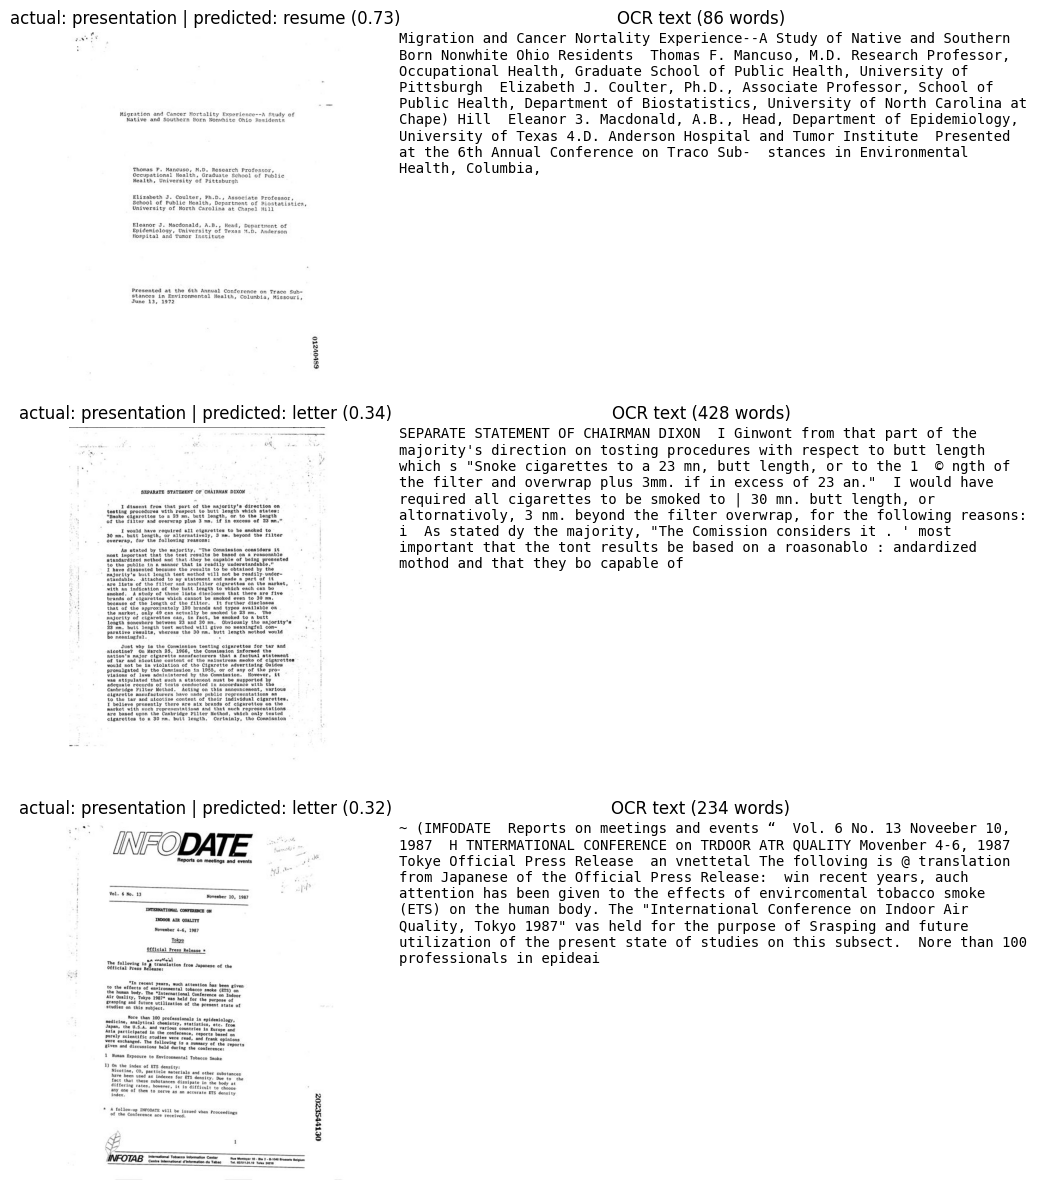

In [16]:
# Look at misclassified presentation pages (weakest class): image next to OCR text
wrong_presentations = errors[errors["label"] == "presentation"].head(3)

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for i, (_, row) in enumerate(wrong_presentations.iterrows()):
    axes[i, 0].imshow(Image.open(data_dir / row["image_path"]), cmap="gray")
    axes[i, 0].set_title(f"actual: {row['label']} | predicted: {row['prediction']} ({row['confidence']:.2f})")
    axes[i, 0].axis("off")

    text = row["ocr_text"] or "[No OCR text extracted]"
    axes[i, 1].text(0, 1, textwrap.fill(text[:600], width=75), va="top", family="monospace")
    axes[i, 1].set_title(f"OCR text ({len(text.split())} words)")
    axes[i, 1].axis("off")
plt.tight_layout()

**Observations (3.3):**
- **Presentation is the main problem:** 15 of its errors go to letter (8) or advertisement (7).
- **Advertisement and letter act as "fallback" classes:** most other errors also land there, which explains their low precision.
- **Short OCR text causes more errors** (accuracy 0.54 for pages under 20 words vs. 0.71 otherwise), **but it is not the whole story:** wrong pages still have a median of 97 words, so most errors happen on pages with plenty of text.
- **Many "presentation" pages do not look like slides.** The misclassified examples are a conference paper title page (predicted resume: names, universities, "Professor"), a typed statement and a newsletter (both predicted letter).
- **The OCR text contains many spelling errors** (e.g. "Noveeber", "envircomental", "roasonablo"), so the same word appears in many broken forms.

**Hypotheses (not yet proven):**

| # | Hypothesis | How we could test it |
|---|---|---|
| H1 | **OCR spelling errors break word features:** a misspelled word becomes a different feature, so the model cannot reuse what it learned. | Use character n-grams (pieces of words), which still match partly misspelled words, and compare with the baseline (Section 3.4). |
| H2 | **The presentation label is ambiguous:** it describes how a document was used (presented at a meeting), not how it looks, so its pages overlap with letters and reports. | Let people label a sample of presentation/letter pages and compare with the dataset labels (annotation part of the course). |
| H3 | **Short or visual pages lack information for a text model:** with little OCR text, the model guesses (often advertisement). | Check whether the page image helps (modality part), or send these pages to human review. |

### 3.4 Improvement experiment: character n-grams (testing H1)

**Hypothesis H1:** OCR spelling errors break word-based features.
**Change:** replace word n-grams with **character n-grams** (3–5 characters within words), which still match partly misspelled words.
**Kept the same:** training data, validation set, classifier (logistic regression, same settings).
**What would support H1:** higher validation macro-F1, especially for classes with noisy OCR.

In [17]:
# Same classifier and data; only the text representation changes (characters instead of words)
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",      # character n-grams inside word boundaries
    ngram_range=(3, 5),
    min_df=2,
    max_features=50_000,
    sublinear_tf=True,
)
X_train_char = char_vectorizer.fit_transform(train_df["ocr_text"])
X_validation_char = char_vectorizer.transform(validation_df["ocr_text"])

char_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1_000,
    random_state=RANDOM_STATE,
)
char_model.fit(X_train_char, train_df["label"])
char_predictions = char_model.predict(X_validation_char)

print("Character n-gram representation:", X_train_char.shape)

Character n-gram representation: (1924, 50000)


In [18]:
# Overall comparison on the same validation set
improvement = pd.DataFrame({
    "Model": ["Baseline (word n-grams)", "Character n-grams"],
    "Accuracy": [
        accuracy_score(validation_df["label"], validation_predictions),
        accuracy_score(validation_df["label"], char_predictions),
    ],
    "Macro-F1": [
        f1_score(validation_df["label"], validation_predictions, average="macro"),
        f1_score(validation_df["label"], char_predictions, average="macro"),
    ],
}).round(3)
display(improvement)

# Per-class F1: which classes improved or got worse?
classes = sorted(validation_df["label"].unique())
per_class = pd.DataFrame({
    "Baseline F1": f1_score(validation_df["label"], validation_predictions, labels=classes, average=None),
    "Char n-gram F1": f1_score(validation_df["label"], char_predictions, labels=classes, average=None),
}, index=classes)
per_class["Change"] = per_class["Char n-gram F1"] - per_class["Baseline F1"]
display(per_class.round(2))

,Model,Accuracy,Macro-F1
0,Baseline (word n-grams),0.681,0.682
1,Character n-grams,0.719,0.726


,Baseline F1,Char n-gram F1,Change
advertisement,0.64,0.63,-0.01
email,0.75,0.80,0.05
form,0.65,0.69,0.04
invoice,0.78,0.83,0.05
letter,0.62,0.64,0.02
news article,0.67,0.70,0.04
presentation,0.43,0.58,0.15
resume,0.91,0.93,0.02


**Observations (3.4):**
- **Character n-grams improve the model:** macro-F1 0.682 → 0.726 (+0.044), accuracy 0.681 → 0.719 (about 9 more validation pages correct out of 235).
- **7 of 8 classes improve, and presentation gains the most** (F1 0.43 → 0.58). This supports **H1**: matching pieces of words helps with noisy OCR text.
- **Advertisement does not improve** (0.64 → 0.63): these pages contain very little text, so a better text representation cannot help. This fits **H3**.
- **Presentation is still the weakest class** (0.58), so **H2** (ambiguous label) remains open.

**Limitations:**
- We compared on one validation set of 235 pages; a gain of ~9 pages may partly be chance.
- Two things changed at once: the type of features (characters instead of words) and their number (50,000 instead of 20,000).

**Decision:** we choose the **character n-gram model** as our final model, based on the validation results only. We now evaluate it on the test set once.

### 3.5 Final evaluation on the test set

The final model (character n-grams) was chosen using the validation set only. We now evaluate it **once** on the reserved test set (241 pages), which was not used for any decision. The word n-gram baseline is shown for reference. We do not change the model after seeing these results.

In [19]:
# Final evaluation: the test set is used here for the first and only time
X_test_word = vectorizer.transform(test_df["ocr_text"])
X_test_char = char_vectorizer.transform(test_df["ocr_text"])

test_baseline_predictions = model.predict(X_test_word)
test_char_predictions = char_model.predict(X_test_char)

final_results = pd.DataFrame({
    "Model": ["Baseline (word n-grams)", "Character n-grams (final)"],
    "Validation macro-F1": [
        f1_score(validation_df["label"], validation_predictions, average="macro"),
        f1_score(validation_df["label"], char_predictions, average="macro"),
    ],
    "Test accuracy": [
        accuracy_score(test_df["label"], test_baseline_predictions),
        accuracy_score(test_df["label"], test_char_predictions),
    ],
    "Test macro-F1": [
        f1_score(test_df["label"], test_baseline_predictions, average="macro"),
        f1_score(test_df["label"], test_char_predictions, average="macro"),
    ],
}).round(3)
display(final_results)

print("Final model, test set, per class:\n")
print(classification_report(test_df["label"], test_char_predictions, zero_division=0))

,Model,Validation macro-F1,Test accuracy,Test macro-F1
0,Baseline (word n-grams),0.682,0.739,0.732
1,Character n-grams (final),0.726,0.763,0.758


Final model, test set, per class:

               precision    recall  f1-score   support

advertisement       0.53      0.86      0.66        29
        email       0.85      0.76      0.80        29
         form       0.81      0.78      0.79        32
      invoice       0.87      0.87      0.87        31
       letter       0.83      0.81      0.82        31
 news article       0.71      0.57      0.63        30
 presentation       0.62      0.48      0.54        27
       resume       0.97      0.94      0.95        32

     accuracy                           0.76       241
    macro avg       0.77      0.76      0.76       241
 weighted avg       0.78      0.76      0.76       241



**Observations (3.5):**
- **The improvement holds on the test set:** character n-grams beat the baseline again (test macro-F1 0.758 vs. 0.732), although the gain is smaller than on validation (+0.026 vs. +0.044).
- **Test scores are higher than validation scores for both models.** With ~30 pages per class, scores vary by a few points between samples; the ranking of the two models is the same.
- **The same weak spots remain:** presentation is the weakest class (F1 0.54, half are missed), and advertisement still has low precision (0.53), acting as a fallback class.

### 3.6 Conclusions

**What we found:**
1. A simple text model (TF-IDF + logistic regression) learns real patterns from OCR text: about 74–76% test accuracy, compared with 12% for the trivial baseline.
2. **Character n-grams** are a better text representation for noisy OCR (supports H1) and are our final model.
3. About **1 in 4 pages is still wrong**, so the system cannot be fully automated.
4. The remaining errors have different causes: **too little text** on visual pages (H3) and an **ambiguous presentation label** (H2). A better text representation alone cannot fix these.
5. The model is **less confident on wrong predictions**, but confidence is low overall and overlaps between correct and wrong predictions.

**What this means for the next parts of the project:**
- **Active learning:** confidence can serve as an uncertainty signal, so uncertainty sampling is worth testing against random sampling. Risk: it may select many ambiguous presentation or near-empty pages, where extra labels help little (aleatoric uncertainty).
- **Annotation:** H2 can be tested by letting people label presentation/letter pages and comparing with the dataset labels.
- **Modality:** H3 suggests that the page image may add information for advertisements and slides.
- **Human review:** low-confidence and near-empty pages are natural candidates to send to a person.